# Análise Exploratória de Dados (EDA) – Wine Quality

A análise exploratória de dados foi realizada com o objetivo de conhecer a estrutura, as características e o comportamento dos dados do dataset Wine Quality, identificando possíveis inconsistências, padrões e relações entre as variáveis antes da aplicação do algoritmo K-Means.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Pasta onde as figuras e tabelas da Parte Comum são salvas
PASTA_SAIDA = "../../out/parte_comum"
os.makedirs(PASTA_SAIDA, exist_ok=True)

In [2]:
df = pd.read_csv("../../data/parte_comum/winequality-red.csv", sep=";")

df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [3]:
df.shape

(1599, 12)

In [4]:
df.columns

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='str')

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


A análise dos tipos de dados identificou 11 variáveis armazenadas como `float64` e uma variável armazenada como `int64`, correspondente à coluna `quality`. Todas as colunas apresentam 1599 valores não nulos. Essas informações permitem verificar como os dados estão armazenados e se há necessidade de ajustes nos tipos de dados antes das próximas etapas.

In [6]:
df.isnull().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

A verificação de dados ausentes não identificou valores nulos em nenhuma das variáveis do dataset. Dessa forma, não foi necessário realizar procedimentos de preenchimento ou remoção de registros em razão de dados ausentes.

In [7]:
quantidade_original = len(df)
quantidade_duplicatas = int(df.duplicated().sum())

resumo_duplicatas = pd.DataFrame({
    "Indicador": [
        "Registros originais",
        "Duplicatas exatas",
        "Registros únicos"
    ],
    "Quantidade": [
        quantidade_original,
        quantidade_duplicatas,
        quantidade_original - quantidade_duplicatas
    ]
})

resumo_duplicatas

,Indicador,Quantidade
0,Registros originais,1599
1,Duplicatas exatas,240
2,Registros únicos,1359


### Análise de registros duplicados

Durante a verificação da qualidade dos dados, foram identificados 240 registros duplicados entre as 1.599 observações do dataset. A presença de registros idênticos não significa necessariamente que existam erros, pois diferentes amostras de vinho podem apresentar os mesmos valores para as características físico-químicas analisadas. Optou-se por manter os registros duplicados, considerando que não há evidências suficientes para classificá-los como erros. A remoção dessas observações poderia modificar a distribuição original dos dados e influenciar os resultados do agrupamento pelo K-Means, uma vez que registros repetidos possuem maior peso na formação dos clusters.

In [8]:
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


As estatísticas descritivas permitem observar aspectos gerais da distribuição das variáveis numéricas, incluindo medidas de tendência central, dispersão e valores extremos. Essas informações contribuem para compreender as características do dataset e auxiliam na identificação de possíveis diferenças de escala entre as variáveis, aspecto relevante para a aplicação do K-Means.

### Análise distribucional

A análise distribucional foi realizada por meio de gráficos de contagem e histogramas, com o objetivo de observar a frequência dos valores, a concentração dos dados e o comportamento das distribuições de cada variável. Essa etapa permite compreender melhor as características do dataset e identificar possíveis padrões e assimetrias.

In [9]:
df["quality"].value_counts().sort_index()

quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64

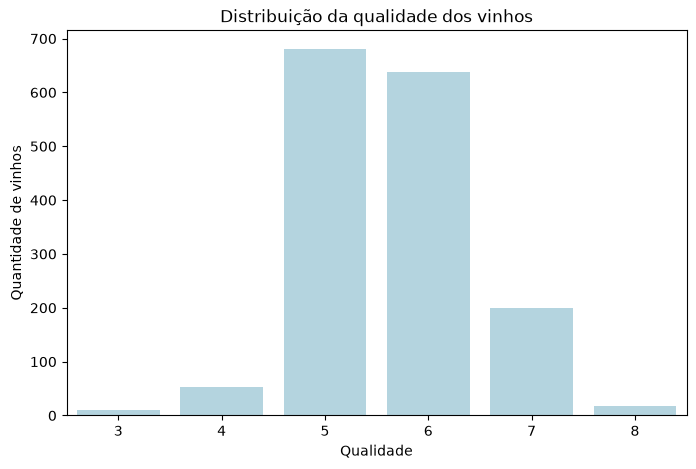

In [10]:
# [IA] ChatGPT – auxílio na implementação e formatação do código de visualização.
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="quality", color="lightblue")

plt.title("Distribuição da qualidade dos vinhos")
plt.xlabel("Qualidade")
plt.ylabel("Quantidade de vinhos")
plt.grid(False)

plt.savefig(f"{PASTA_SAIDA}/01_distribuicao_qualidade.png", dpi=150, bbox_inches="tight")
plt.show()

A distribuição da variável `quality` indica uma maior concentração de vinhos classificados com notas 5 e 6, sendo a nota 5 a mais frequente. Em contrapartida, as notas 3 e 8 apresentam uma quantidade significativamente menor de registros. Dessa forma, observa-se que as classes de qualidade estão distribuídas de maneira desigual no dataset.

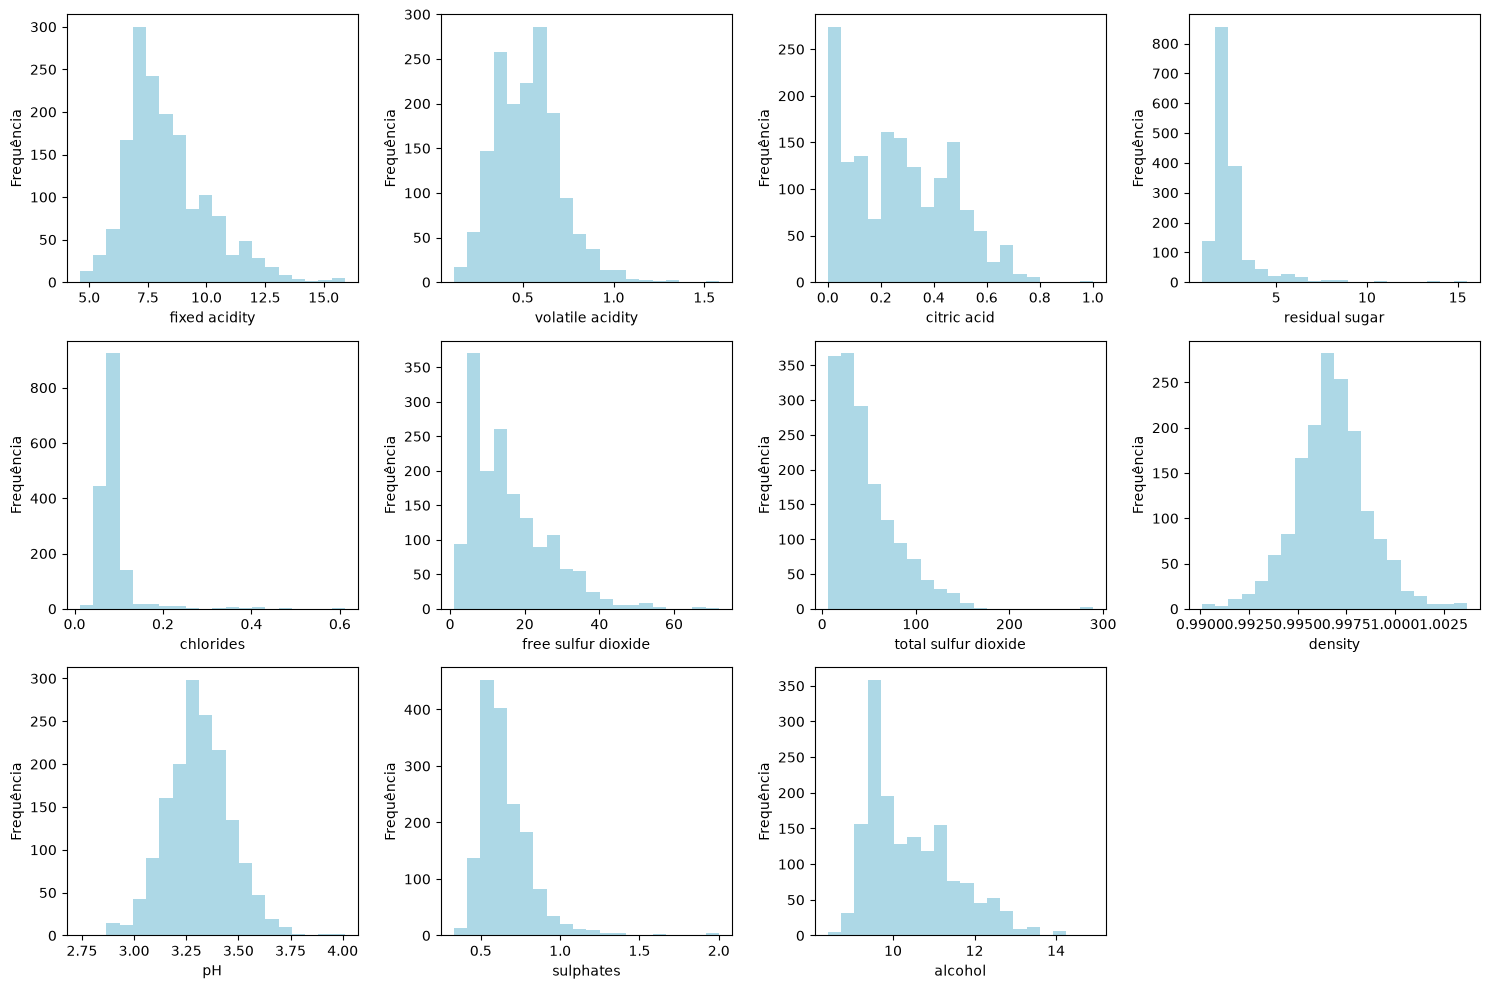

In [11]:
# [IA] ChatGPT – auxílio na implementação e formatação do código de visualização.
colunas = df.drop(columns="quality").columns

fig, axes = plt.subplots(3, 4, figsize=(15, 10))

for ax, coluna in zip(axes.flatten(), colunas):
    ax.hist(df[coluna], bins=20, color="lightblue")
    ax.set_xlabel(coluna)
    ax.set_ylabel("Frequência")
    ax.grid(False)

axes.flatten()[-1].set_visible(False)

plt.tight_layout()
plt.savefig(f"{PASTA_SAIDA}/02_histogramas.png", dpi=150, bbox_inches="tight")
plt.show()

A análise dos histogramas revelou que algumas variáveis apresentam distribuições assimétricas, com maior concentração de valores em faixas menores e uma cauda à direita, como observado em `residual sugar`, `chlorides`, `free sulfur dioxide`, `total sulfur dioxide` e `sulphates`. Outras variáveis, como `density` e `pH`, apresentam distribuições mais concentradas e relativamente simétricas. Essas diferenças demonstram que as variáveis possuem comportamentos e distribuições distintas.

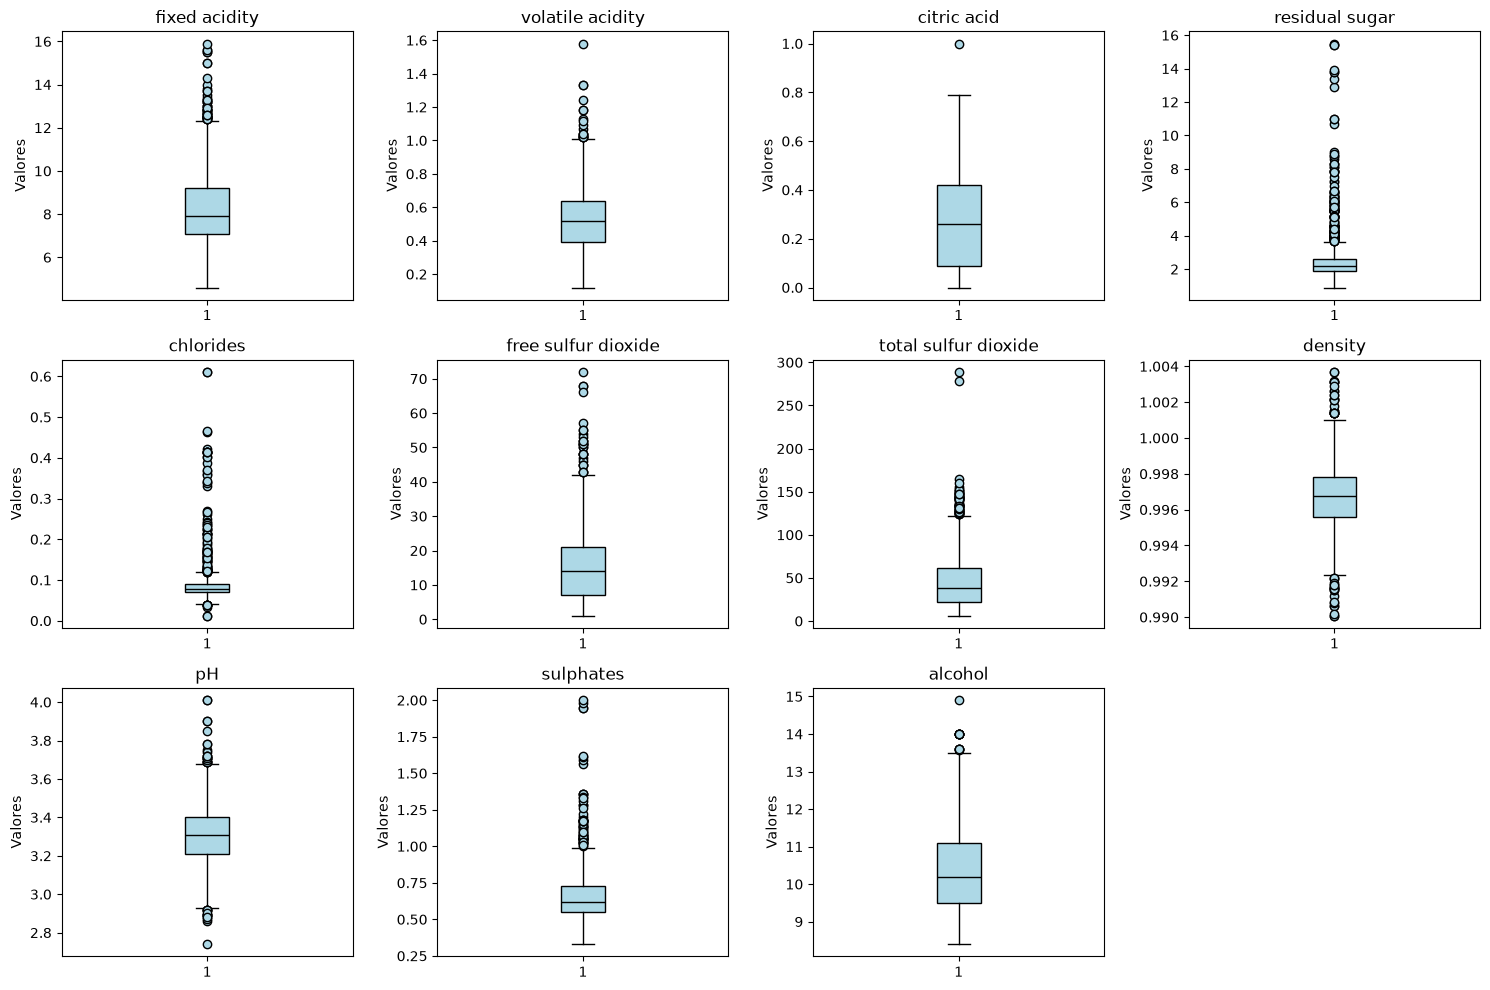

In [12]:
# [IA] ChatGPT – auxílio na implementação e formatação do código de visualização.
colunas = df.drop(columns="quality").columns

fig, axes = plt.subplots(3, 4, figsize=(15, 10))

for ax, coluna in zip(axes.flatten(), colunas):
    ax.boxplot(
        df[coluna],
        patch_artist=True,
        boxprops=dict(facecolor="lightblue"),
        medianprops=dict(color="black"),
        whiskerprops=dict(color="black"),
        capprops=dict(color="black"),
        flierprops=dict(markerfacecolor="lightblue", markeredgecolor="black")
    )
    ax.set_title(coluna)
    ax.set_ylabel("Valores")
    ax.grid(False)

axes.flatten()[-1].set_visible(False)

plt.tight_layout()
plt.savefig(f"{PASTA_SAIDA}/03_boxplots.png", dpi=150, bbox_inches="tight")
plt.show()

Os boxplots permitiram visualizar a presença de possíveis outliers em diferentes variáveis do dataset. Observou-se que algumas apresentam pontos mais distantes da concentração principal dos dados, especialmente `residual sugar`, `chlorides` e `sulphates`. Também foram identificados possíveis outliers em outras variáveis. 

In [13]:
colunas = df.drop(columns="quality").columns

outliers = {}

for coluna in colunas:
    q1 = df[coluna].quantile(0.25)
    q3 = df[coluna].quantile(0.75)
    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    quantidade = ((df[coluna] < limite_inferior) | (df[coluna] > limite_superior)).sum()

    outliers[coluna] = quantidade

pd.Series(outliers, name="Quantidade de possíveis outliers")

fixed acidity            49
volatile acidity         19
citric acid               1
residual sugar          155
chlorides               112
free sulfur dioxide      30
total sulfur dioxide     55
density                  45
pH                       35
sulphates                59
alcohol                  13
Name: Quantidade de possíveis outliers, dtype: int64

In [14]:
resultado_outliers = pd.DataFrame(outliers.items(), columns=["Variável", "Quantidade"])

resultado_outliers["Porcentagem"] = (resultado_outliers["Quantidade"] / len(df)) * 100

resultado_outliers

,Variável,Quantidade,Porcentagem
0,fixed acidity,49,3.064415
1,volatile acidity,19,1.188243
2,citric acid,1,0.062539
3,residual sugar,155,9.693558
4,chlorides,112,7.004378
5,free sulfur dioxide,30,1.876173
6,total sulfur dioxide,55,3.439650
7,density,45,2.814259
8,pH,35,2.188868
9,sulphates,59,3.689806


A quantificação dos possíveis outliers pelo método IQR evidenciou diferenças entre as variáveis analisadas. As variáveis `residual sugar` e `chlorides` apresentaram as maiores quantidades de possíveis outliers, com 155 e 112 registros, respectivamente. Outras variáveis, como `sulphates`, `total sulfur dioxide` e `fixed acidity`, também apresentaram valores identificados pelo método. Esses resultados indicam a presença de observações mais distantes da distribuição central em determinadas características físico-químicas do dataset.

### Tratamento dos outliers

Optou-se por manter os possíveis outliers identificados pelo método IQR, sem realizar sua remoção ou substituição. Essa decisão considera que valores estatisticamente atípicos não representam necessariamente erros nos dados. Entretanto, sua presença pode influenciar os resultados do K-Means, já que o algoritmo utiliza distâncias para formar os agrupamentos e é sensível a valores extremos.

### Análise relacional

Nesta etapa, foram exploradas as relações entre as variáveis numéricas do dataset por meio da matriz de correlação e de gráficos de dispersão. A matriz permitiu visualizar as correlações entre as variáveis, enquanto os gráficos de dispersão foram utilizados para observar individualmente algumas dessas relações.

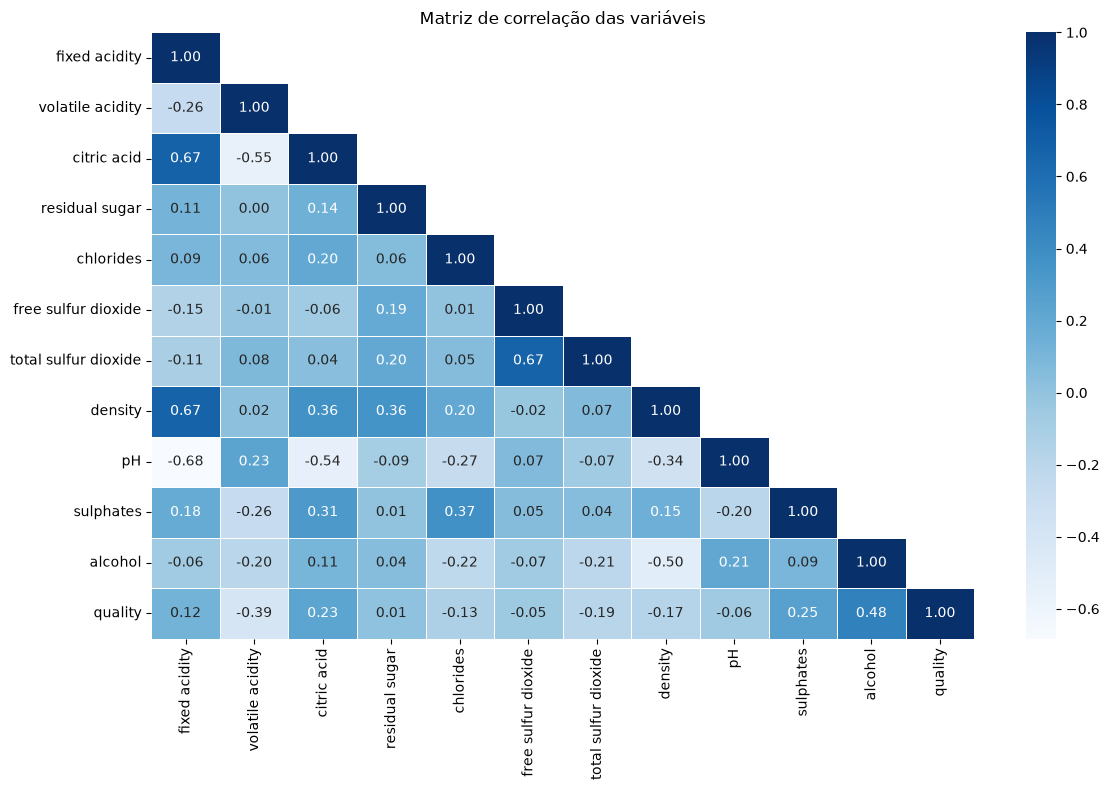

In [15]:
# [IA] ChatGPT – auxílio na implementação e formatação do código de visualização.
correlacao = df.corr()

mascara = np.triu(np.ones_like(correlacao, dtype=bool), k=1)

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlacao,
    mask=mascara,
    annot=True,
    cmap="Blues",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Matriz de correlação das variáveis")
plt.grid(False)

plt.tight_layout()
plt.savefig(f"{PASTA_SAIDA}/04_matriz_correlacao.png", dpi=150, bbox_inches="tight")
plt.show()

A matriz de correlação permitiu observar diferentes níveis de associação linear entre as variáveis. Em relação à variável `quality`, destacam-se `alcohol`, com correlação positiva, e `volatile acidity`, com correlação negativa, indicando que essas variáveis apresentam associações lineares mais evidentes com a qualidade dos vinhos dentro do dataset. Entretanto, essas correlações não implicam necessariamente uma relação de causalidade.

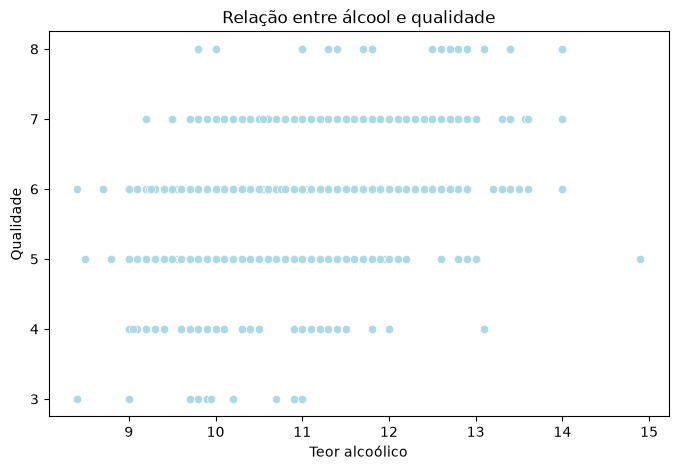

In [16]:
# [IA] ChatGPT – auxílio na implementação e formatação do código de visualização.
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="alcohol", y="quality", color="lightblue")

plt.title("Relação entre álcool e qualidade")
plt.xlabel("Teor alcoólico")
plt.ylabel("Qualidade")
plt.grid(False)

plt.savefig(f"{PASTA_SAIDA}/05_dispersao_alcool_qualidade.png", dpi=150, bbox_inches="tight")
plt.show()

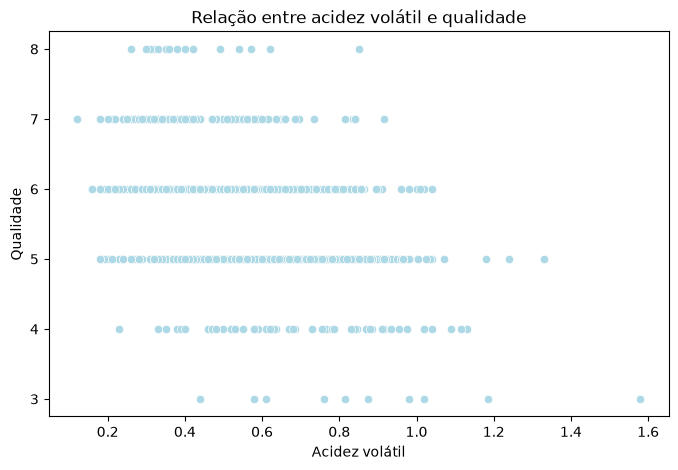

In [17]:
# [IA] ChatGPT – auxílio na implementação e formatação do código de visualização.
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="volatile acidity", y="quality", color="lightblue")

plt.title("Relação entre acidez volátil e qualidade")
plt.xlabel("Acidez volátil")
plt.ylabel("Qualidade")
plt.grid(False)

plt.savefig(f"{PASTA_SAIDA}/06_dispersao_acidez_volatil_qualidade.png", dpi=150, bbox_inches="tight")
plt.show()

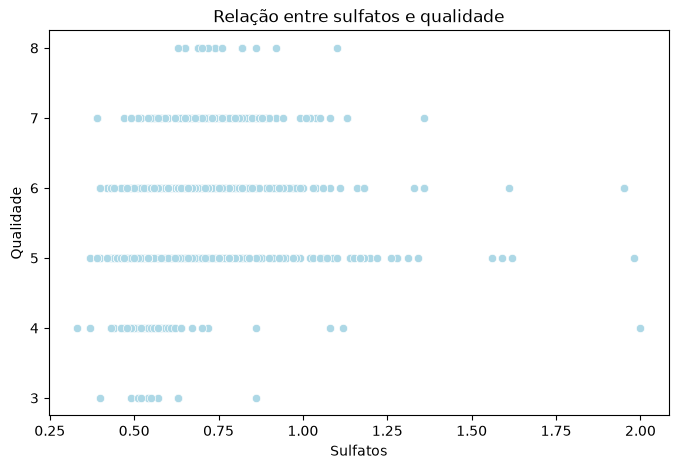

In [18]:
# [IA] ChatGPT – auxílio na implementação e formatação do código de visualização.
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="sulphates", y="quality", color="lightblue")

plt.title("Relação entre sulfatos e qualidade")
plt.xlabel("Sulfatos")
plt.ylabel("Qualidade")
plt.grid(False)

plt.savefig(f"{PASTA_SAIDA}/07_dispersao_sulfatos_qualidade.png", dpi=150, bbox_inches="tight")
plt.show()

Os gráficos de dispersão complementam a análise da matriz de correlação, permitindo observar as associações entre algumas características físico-químicas e a qualidade dos vinhos. A variável `alcohol` apresenta uma tendência positiva em relação à `quality`, enquanto `volatile acidity` apresenta uma tendência negativa. Já `sulphates` demonstra uma associação positiva menos evidente. Essas observações reforçam os resultados identificados na matriz de correlação, embora não indiquem relações de causalidade.

### Padronização dos dados

Antes da aplicação do K-Means, as variáveis físico-químicas serão padronizadas utilizando o `StandardScaler`, de modo que cada variável apresente média aproximadamente zero e desvio padrão igual a um. A padronização é necessária porque o K-Means utiliza distâncias euclidianas para formar os agrupamentos. Como as variáveis possuem escalas diferentes, esse procedimento evita que aquelas com valores numericamente maiores exerçam influência desproporcional no cálculo das distâncias.

In [19]:
# [IA] ChatGPT – apoio na utilização do StandardScaler para padronização das variáveis.
from sklearn.preprocessing import StandardScaler


X = df.drop(columns="quality")
scaler = StandardScaler()
X_padronizado = scaler.fit_transform(X)
df_padronizado = pd.DataFrame(
    X_padronizado,
    columns=X.columns
)

df_padronizado.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,-0.528360,0.961877,-1.391472,-0.453218,-0.243707,-0.466193,-0.379133,0.558274,1.288643,-0.579207,-0.960246
1,-0.298547,1.967442,-1.391472,0.043416,0.223875,0.872638,0.624363,0.028261,-0.719933,0.128950,-0.584777
2,-0.298547,1.297065,-1.186070,-0.169427,0.096353,-0.083669,0.229047,0.134264,-0.331177,-0.048089,-0.584777
3,1.654856,-1.384443,1.484154,-0.453218,-0.264960,0.107592,0.411500,0.664277,-0.979104,-0.461180,-0.584777
4,-0.528360,0.961877,-1.391472,-0.453218,-0.243707,-0.466193,-0.379133,0.558274,1.288643,-0.579207,-0.960246


In [20]:
df_padronizado.agg(["mean", "std"]).round(3)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
mean,0.0,0.0,-0.0,-0.0,0.0,-0.0,0.0,-0.0,0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


### Método do Cotovelo

Para determinar um número adequado de clusters, será utilizado o Método do Cotovelo, testando valores de `k` entre 2 e 10. O método analisa a inércia, que representa a soma das distâncias quadráticas das observações aos centroides de seus respectivos clusters. O objetivo é identificar um ponto a partir do qual o aumento do número de clusters proporciona reduções cada vez menores na inércia, auxiliando na escolha de um valor adequado para `k`.

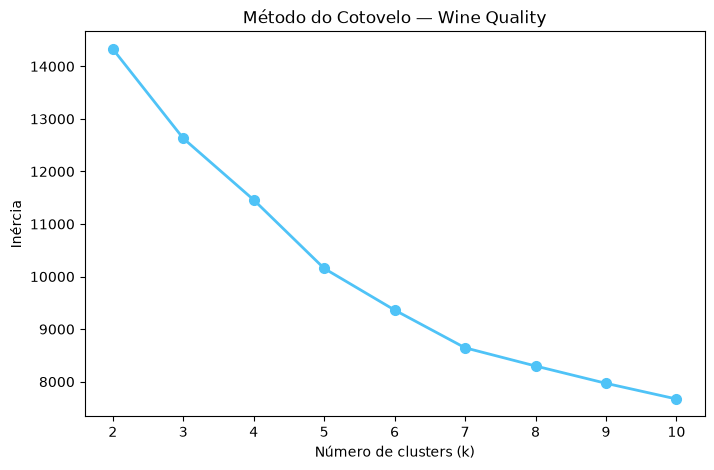

In [21]:
# [IA] ChatGPT – auxílio na implementação do Método do Cotovelo com scikit-learn.
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

valores_k = range(2, 11)
inercias = []

for k in valores_k:
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    modelo.fit(X_padronizado)
    inercias.append(modelo.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(
    valores_k,
    inercias,
    marker="o",
    color="#4FC3F7",
    linewidth=2,
    markersize=7
)

plt.title("Método do Cotovelo — Wine Quality")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Inércia")
plt.xticks(list(valores_k))
plt.grid(False)

plt.savefig(f"{PASTA_SAIDA}/08_metodo_cotovelo.png", dpi=150, bbox_inches="tight")
plt.show()

In [22]:
# [IA] Claude – apoio no cálculo da queda percentual da inércia entre valores consecutivos de k.
tabela_cotovelo = pd.DataFrame({
    "k": list(valores_k),
    "Inércia": inercias
})
tabela_cotovelo["Queda em relação ao k anterior (%)"] = (
    -tabela_cotovelo["Inércia"].pct_change() * 100
)

tabela_cotovelo.round(1)

,k,Inércia,Queda em relação ao k anterior (%)
0,2,14330.1,NaN
1,3,12630.0,11.9
2,4,11459.1,9.3
3,5,10155.5,11.4
4,6,9363.2,7.8
5,7,8645.2,7.7
6,8,8299.0,4.0
7,9,7969.3,4.0
8,10,7671.0,3.7


A curva não apresenta um "cotovelo" muito acentuado, o que já indica que os dados não se separam em grupos muito bem definidos. Ainda assim, a tabela mostra que a inércia cai de forma expressiva até `k = 5` (queda de cerca de 11% de 4 para 5 clusters) e que, a partir de `k = 6`, as reduções ficam menores (cerca de 8% e, depois de `k = 7`, apenas 4%). Por isso, `k = 5` foi escolhido como o ponto em que adicionar novos clusters deixa de trazer ganhos relevantes.

### Primeira passada do K-Means — k livre

Nesta etapa, o algoritmo K-Means será executado utilizando k = 5, valor selecionado após a avaliação do Método do Cotovelo. O agrupamento será realizado com as variáveis físico-químicas padronizadas, sem utilizar a variável `quality`, que será reservada para a avaliação posterior dos resultados.

In [23]:
# [IA] ChatGPT – auxílio na implementação e configuração do K-Means com scikit-learn.
k_livre = 5

kmeans_livre = KMeans(
    n_clusters=k_livre,
    random_state=42,
    n_init=10
)

clusters_livre = kmeans_livre.fit_predict(X_padronizado)

pd.Series(clusters_livre).value_counts().sort_index()

0    337
1    553
2    311
3    370
4     28
Name: count, dtype: int64

### Visualização dos clusters — k livre

Para visualizar os agrupamentos encontrados pelo K-Means, será utilizada a Análise de Componentes Principais (PCA), reduzindo os dados para duas dimensões.

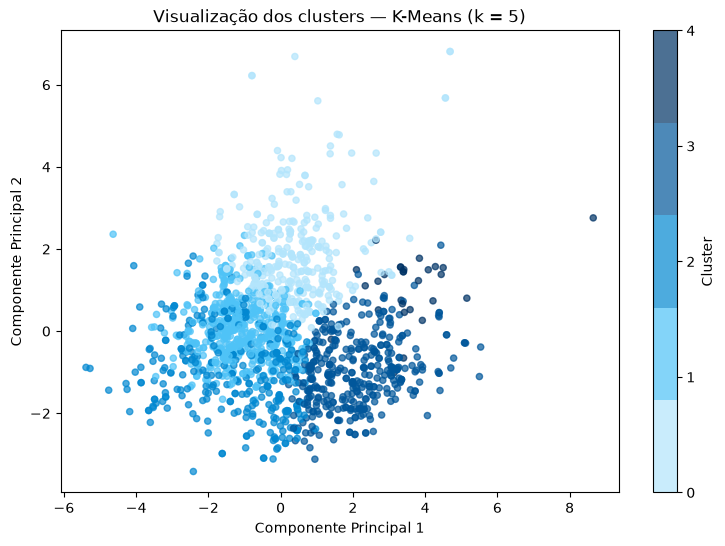

In [24]:
# [IA] ChatGPT – auxílio na implementação da visualização dos clusters com PCA e na formatação do gráfico.
from sklearn.decomposition import PCA
from matplotlib.colors import ListedColormap

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_padronizado)

cores = [
    "#B3E5FC",  
    "#4FC3F7",  
    "#0288D1",  
    "#01579B",  
    "#003366"   
]
cmap_azul = ListedColormap(cores)

plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=clusters_livre,
    cmap=cmap_azul,
    alpha=0.7,
    s=20
)

plt.title("Visualização dos clusters — K-Means (k = 5)")
plt.xlabel("Componente Principal 1")
plt.ylabel("Componente Principal 2")

plt.colorbar(scatter, label="Cluster", ticks=range(k_livre))

plt.grid(False)
plt.savefig(f"{PASTA_SAIDA}/09_clusters_pca_k5.png", dpi=150, bbox_inches="tight")
plt.show()

### Segunda passada do K-Means — k fixo

Nesta etapa, o K-Means será executado novamente, fixando o número de clusters em k = 6, correspondente à quantidade de classes reais presentes na variável `quality`.

In [25]:
# [IA] ChatGPT – auxílio na implementação e configuração do K-Means com scikit-learn.
k_fixo = df["quality"].nunique()

kmeans_fixo = KMeans(
    n_clusters=k_fixo,
    random_state=42,
    n_init=10
)

clusters_fixo = kmeans_fixo.fit_predict(X_padronizado)

pd.Series(clusters_fixo).value_counts().sort_index()

0     34
1     30
2    302
3    533
4    338
5    362
Name: count, dtype: int64

### Visualização dos clusters — k fixo

Para visualizar os seis agrupamentos obtidos na segunda passada do K-Means, será utilizada a mesma projeção PCA da primeira passada. Isso permite representar os dois resultados no mesmo espaço bidimensional, facilitando sua comparação visual. 

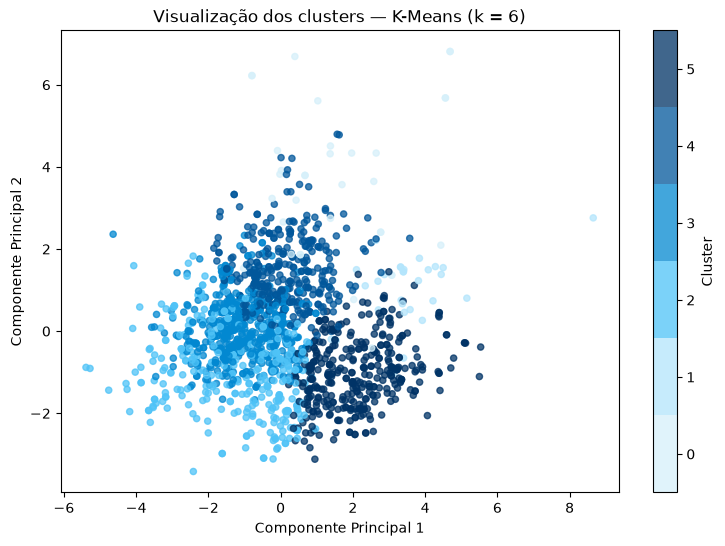

In [26]:
# [IA] ChatGPT – auxílio na implementação da visualização dos clusters com PCA e na formatação do gráfico.
from matplotlib.colors import ListedColormap

cores_fixo = [
    "#D6F0FA",
    "#B3E5FC",
    "#4FC3F7",
    "#0288D1",
    "#01579B",
    "#003366"
]

cmap_fixo = ListedColormap(cores_fixo)

plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=clusters_fixo,
    cmap=cmap_fixo,
    vmin=-0.5,
    vmax=k_fixo - 0.5,
    alpha=0.75,
    s=20
)

plt.title("Visualização dos clusters — K-Means (k = 6)")
plt.xlabel("Componente Principal 1")
plt.ylabel("Componente Principal 2")

plt.colorbar(scatter, label="Cluster", ticks=range(k_fixo))

plt.grid(False)
plt.savefig(f"{PASTA_SAIDA}/10_clusters_pca_k6.png", dpi=150, bbox_inches="tight")
plt.show()

### Avaliação dos agrupamentos

Para avaliar os resultados do K-Means, os clusters encontrados serão comparados com as classes reais da variável `quality`. Como o K-Means é um algoritmo não supervisionado, os identificadores dos clusters não correspondem diretamente às classes reais do dataset. Por isso, cada cluster será associado à classe de qualidade mais frequente entre seus registros, procedimento conhecido como mapeamento pela classe majoritária. Esse mapeamento permitirá construir as matrizes de confusão e calcular as métricas de acurácia, precisão e recall para as duas passadas.

In [27]:
# [IA] ChatGPT – apoio na implementação da função de mapeamento dos clusters pela classe majoritária.
def mapear_clusters(clusters, classes_reais):
    tabela = pd.DataFrame({
        "cluster": clusters,
        "classe_real": classes_reais
    })

    mapeamento = (
        tabela.groupby("cluster")["classe_real"]
        .agg(lambda valores: valores.value_counts().idxmax())
        .to_dict()
    )

    classes_previstas = pd.Series(clusters).map(mapeamento)

    return mapeamento, classes_previstas


classes_reais = df["quality"].reset_index(drop=True)

mapeamento_livre, previsoes_livre = mapear_clusters(
    clusters_livre, classes_reais
)

mapeamento_fixo, previsoes_fixo = mapear_clusters(
    clusters_fixo, classes_reais
)

print("Mapeamento — k livre:")
print(mapeamento_livre)

print("\nMapeamento — k fixo:")
print(mapeamento_fixo)

Mapeamento — k livre:
{0: 5, 1: 5, 2: 6, 3: 6, 4: 5}

Mapeamento — k fixo:
{0: 5, 1: 5, 2: 6, 3: 5, 4: 5, 5: 6}


### Matrizes de confusão

As matrizes de confusão serão utilizadas para comparar as classes reais dos vinhos com as classes atribuídas aos clusters após o mapeamento pela classe majoritária. Serão apresentadas duas matrizes, uma para a primeira passada (k = 5) e outra para a segunda passada (k = 6), permitindo visualizar a distribuição dos acertos e das divergências entre os agrupamentos e as classes originais.

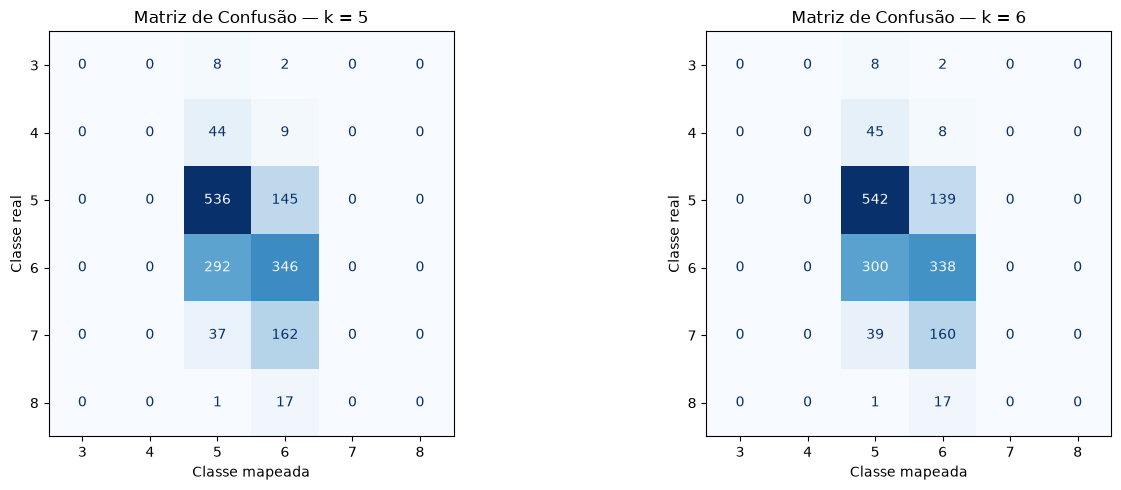

In [28]:
# [IA] ChatGPT – auxílio na implementação e formatação das matrizes de confusão.
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

classes = sorted(classes_reais.unique())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

matriz_livre = confusion_matrix(
    classes_reais,
    previsoes_livre,
    labels=classes
)

matriz_fixo = confusion_matrix(
    classes_reais,
    previsoes_fixo,
    labels=classes
)

ConfusionMatrixDisplay(
    confusion_matrix=matriz_livre,
    display_labels=classes
).plot(
    ax=axes[0],
    cmap="Blues",
    colorbar=False,
    values_format="d"
)

axes[0].set_title("Matriz de Confusão — k = 5")
axes[0].set_xlabel("Classe mapeada")
axes[0].set_ylabel("Classe real")
axes[0].grid(False)

ConfusionMatrixDisplay(
    confusion_matrix=matriz_fixo,
    display_labels=classes
).plot(
    ax=axes[1],
    cmap="Blues",
    colorbar=False,
    values_format="d"
)

axes[1].set_title("Matriz de Confusão — k = 6")
axes[1].set_xlabel("Classe mapeada")
axes[1].set_ylabel("Classe real")
axes[1].grid(False)

plt.tight_layout()
plt.savefig(f"{PASTA_SAIDA}/11_matrizes_confusao.png", dpi=150, bbox_inches="tight")
plt.show()

### Distribuição das classes reais dentro de cada cluster

A matriz de confusão compara a classe mapeada com a classe real. Para entender **por que** o mapeamento ficou assim, também é útil observar diretamente quantos vinhos de cada nota caíram em cada cluster. Na Passada 1 essa tabela é retangular (5 clusters × 6 classes), e na Passada 2 é quadrada (6 × 6).

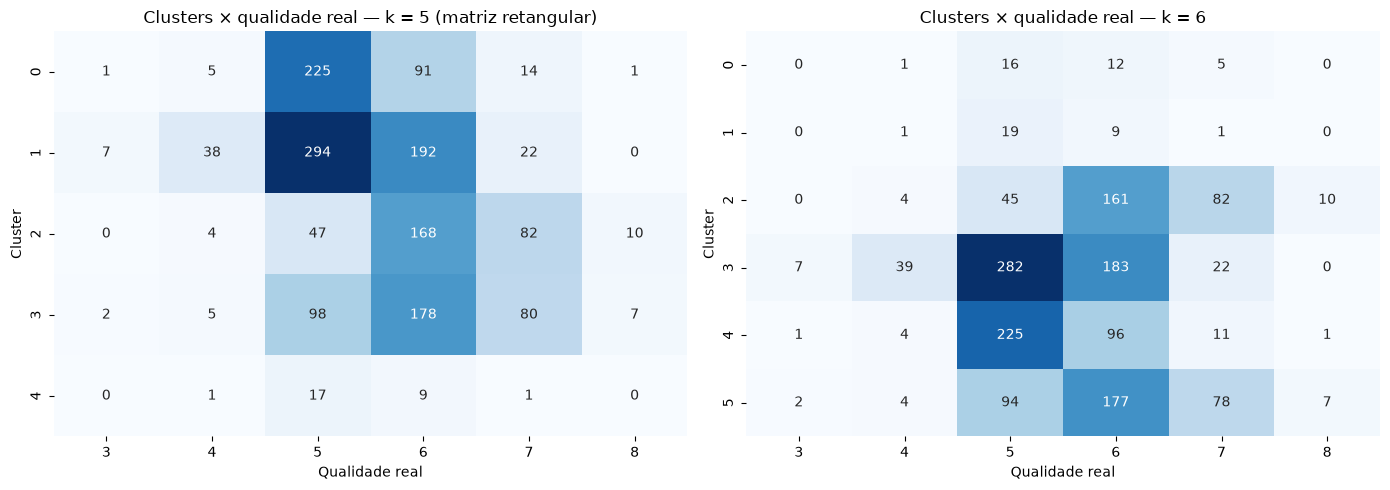

In [29]:
# [IA] Claude – apoio na construção das tabelas cluster × classe real e na formatação dos heatmaps.
tabela_livre = pd.crosstab(clusters_livre, classes_reais.values,
                           rownames=["Cluster"], colnames=["Qualidade real"])
tabela_fixo = pd.crosstab(clusters_fixo, classes_reais.values,
                          rownames=["Cluster"], colnames=["Qualidade real"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(tabela_livre, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0])
axes[0].set_title("Clusters × qualidade real — k = 5 (matriz retangular)")
axes[0].set_xlabel("Qualidade real")
axes[0].set_ylabel("Cluster")

sns.heatmap(tabela_fixo, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[1])
axes[1].set_title("Clusters × qualidade real — k = 6")
axes[1].set_xlabel("Qualidade real")
axes[1].set_ylabel("Cluster")

plt.tight_layout()
plt.savefig(f"{PASTA_SAIDA}/12_clusters_x_classes.png", dpi=150, bbox_inches="tight")
plt.show()

Nenhum cluster é dominado por uma única nota. Mesmo os clusters mais "puros" têm cerca de 67% de vinhos de nota 5, e os clusters associados à nota 6 têm apenas cerca de 50% de vinhos dessa nota. As notas 3, 4, 7 e 8 aparecem espalhadas por vários clusters e nunca são a maioria em nenhum deles, por isso nunca são escolhidas no mapeamento pela classe majoritária.

###  Métricas de avaliação dos agrupamentos

A partir dos rótulos obtidos pelo mapeamento dos clusters, serão calculadas as métricas de acurácia, precisão e recall para as duas passadas do K-Means. A acurácia representa a proporção geral de classificações corretas. A precisão indica a proporção de acertos entre os registros atribuídos a determinada classe, enquanto o recall representa a proporção de registros corretamente identificados entre aqueles que realmente pertencem à classe.



In [30]:
# [IA] ChatGPT – apoio na implementação do cálculo de acurácia, precisão e recall.
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

def calcular_metricas(classes_reais, previsoes, classes):
    acuracia = accuracy_score(classes_reais, previsoes)

    precisao, recall, _, suporte = precision_recall_fscore_support(
        classes_reais,
        previsoes,
        labels=classes,
        zero_division=0
    )

    metricas = pd.DataFrame({
        "Classe": classes,
        "Precisão": precisao,
        "Recall": recall,
        "Quantidade real": suporte
    })

    return acuracia, metricas


acuracia_livre, metricas_livre = calcular_metricas(
    classes_reais, previsoes_livre, classes
)

acuracia_fixo, metricas_fixo = calcular_metricas(
    classes_reais, previsoes_fixo, classes
)

print(f"Acurácia — k = 5: {acuracia_livre:.2%}")
display(metricas_livre.round(3))

print(f"Acurácia — k = 6: {acuracia_fixo:.2%}")
display(metricas_fixo.round(3))

Acurácia — k = 5: 55.16%


,Classe,Precisão,Recall,Quantidade real
0,3,0.000,0.000,10
1,4,0.000,0.000,53
2,5,0.584,0.787,681
3,6,0.508,0.542,638
4,7,0.000,0.000,199
5,8,0.000,0.000,18


Acurácia — k = 6: 55.03%


,Classe,Precisão,Recall,Quantidade real
0,3,0.000,0.000,10
1,4,0.000,0.000,53
2,5,0.580,0.796,681
3,6,0.509,0.530,638
4,7,0.000,0.000,199
5,8,0.000,0.000,18


### Comparação com uma referência simples

Como a nota 5 representa cerca de 43% do dataset, é importante comparar a acurácia obtida com a de uma regra trivial que atribui a nota 5 a todos os vinhos. Isso mostra quanto da acurácia vem realmente da estrutura encontrada pelo K-Means.

In [31]:
# [IA] Claude – apoio no cálculo da acurácia de referência (classe mais frequente).
classe_mais_frequente = classes_reais.value_counts().idxmax()
acuracia_referencia = (classes_reais == classe_mais_frequente).mean()

print(f"Acurácia de referência (sempre nota {classe_mais_frequente}): {acuracia_referencia:.2%}")
print(f"Acurácia — k = 5: {acuracia_livre:.2%}")
print(f"Acurácia — k = 6: {acuracia_fixo:.2%}")

# Exporta as tabelas de métricas
metricas_livre.to_csv(f"{PASTA_SAIDA}/metricas_k5.csv", index=False)
metricas_fixo.to_csv(f"{PASTA_SAIDA}/metricas_k6.csv", index=False)

Acurácia de referência (sempre nota 5): 42.59%
Acurácia — k = 5: 55.16%
Acurácia — k = 6: 55.03%


### Comparação das duas passadas do K-Means

Nesta etapa, serão reunidos os resultados das duas execuções do K-Means para apoiar a comparação entre o número de clusters selecionado pelo Método do Cotovelo e o número de classes reais do dataset.

In [32]:
# [IA] ChatGPT – auxílio na organização dos resultados em uma tabela comparativa.
comparacao = pd.DataFrame({
    "Passada": ["k livre", "k fixo"],
    "Número de clusters": [k_livre, k_fixo],
    "Inércia": [kmeans_livre.inertia_, kmeans_fixo.inertia_],
    "Acurácia (%)": [acuracia_livre * 100, acuracia_fixo * 100]
})

comparacao.round(2)

,Passada,Número de clusters,Inércia,Acurácia (%)
0,k livre,5,10155.51,55.16
1,k fixo,6,9363.21,55.03


In [33]:
# [IA] Claude – apoio na exportação da tabela comparativa.
comparacao.round(2).to_csv(f"{PASTA_SAIDA}/comparacao_passadas.csv", index=False)

### Granularidade das classes: as notas são distinguíveis pelos dados?

Para investigar se as seis notas de qualidade fazem sentido do ponto de vista dos dados, foram observadas as duas variáveis mais correlacionadas com `quality` (`alcohol` e `volatile acidity`) em cada nota.

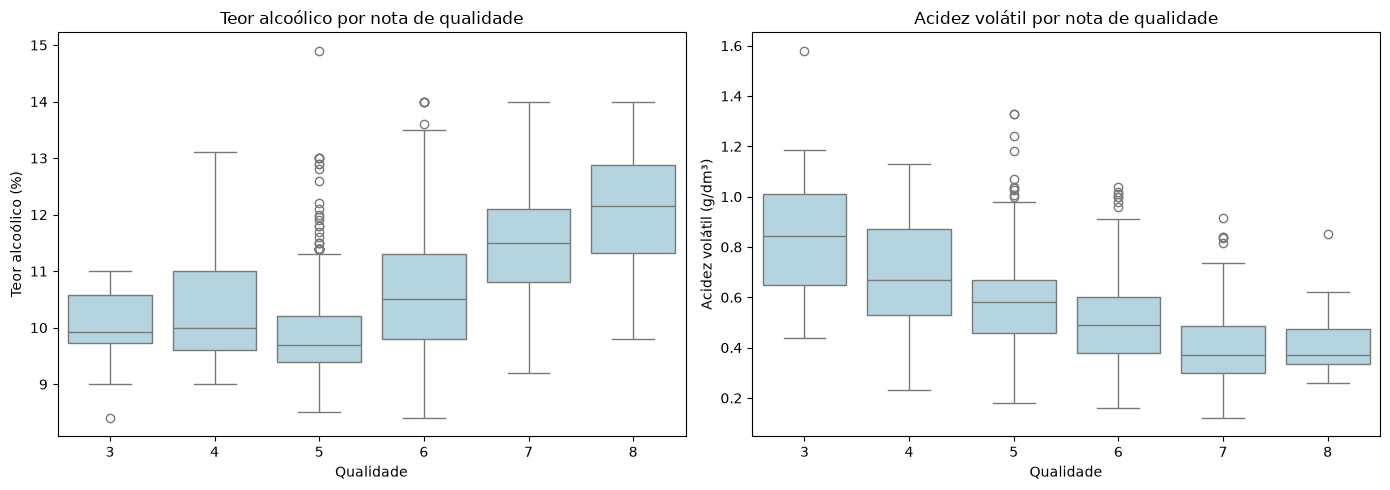

alcohol       volatile acidity      
           mean   std             mean   std
quality                                     
3          9.96  0.82             0.88  0.33
4         10.27  0.93             0.69  0.22
5          9.90  0.74             0.58  0.16
6         10.63  1.05             0.50  0.16
7         11.47  0.96             0.40  0.15
8         12.09  1.22             0.42  0.14

In [34]:
# [IA] Claude – apoio na implementação e formatação dos boxplots por nota de qualidade.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df, x="quality", y="alcohol", color="lightblue", ax=axes[0])
axes[0].set_title("Teor alcoólico por nota de qualidade")
axes[0].set_xlabel("Qualidade")
axes[0].set_ylabel("Teor alcoólico (%)")

sns.boxplot(data=df, x="quality", y="volatile acidity", color="lightblue", ax=axes[1])
axes[1].set_title("Acidez volátil por nota de qualidade")
axes[1].set_xlabel("Qualidade")
axes[1].set_ylabel("Acidez volátil (g/dm³)")

plt.tight_layout()
plt.savefig(f"{PASTA_SAIDA}/13_alcool_acidez_por_qualidade.png", dpi=150, bbox_inches="tight")
plt.show()

df.groupby("quality")[["alcohol", "volatile acidity"]].agg(["mean", "std"]).round(2)

Existe uma tendência clara entre os extremos (vinhos de nota 7–8 têm mais álcool e menos acidez volátil que os de nota 3–4), mas as caixas das notas vizinhas se sobrepõem bastante. Entre as notas 5 e 6, a diferença média de álcool é de cerca de 0,7 ponto percentual, menor que o desvio padrão dentro de cada nota (aproximadamente 0,7 a 1,0). Ou seja, um vinho de nota 5 e um de nota 6 costumam ter perfis físico-químicos muito parecidos.

Como teste complementar, as notas foram reagrupadas em três faixas (baixa: 3–4; média: 5–6; alta: 7–8) e o mesmo procedimento de mapeamento foi aplicado aos clusters da Passada 1.

In [35]:
# [IA] Claude – apoio na implementação do reagrupamento das notas em três faixas.
def faixa_qualidade(nota):
    if nota <= 4:
        return "baixa (3-4)"
    if nota <= 6:
        return "média (5-6)"
    return "alta (7-8)"

faixas_reais = classes_reais.map(faixa_qualidade)
print(faixas_reais.value_counts())

mapeamento_faixas, previsoes_faixas = mapear_clusters(clusters_livre, faixas_reais)
print("\nMapeamento dos clusters (k = 5) para as faixas:", mapeamento_faixas)

acuracia_faixas = accuracy_score(faixas_reais, previsoes_faixas)
referencia_faixas = (faixas_reais == "média (5-6)").mean()
print(f"Acurácia com 3 faixas: {acuracia_faixas:.2%}")
print(f"Acurácia de referência (sempre 'média'): {referencia_faixas:.2%}")

quality
média (5-6)    1319
alta (7-8)      217
baixa (3-4)      63
Name: count, dtype: int64

Mapeamento dos clusters (k = 5) para as faixas: {0: 'média (5-6)', 1: 'média (5-6)', 2: 'média (5-6)', 3: 'média (5-6)', 4: 'média (5-6)'}
Acurácia com 3 faixas: 82.49%
Acurácia de referência (sempre 'média'): 82.49%


Com três faixas, a acurácia sobe para cerca de 82%, mas esse valor é **igual** ao de simplesmente classificar todos os vinhos como "média", já que todos os clusters passam a ser mapeados para essa faixa. Isso mostra que a acurácia, sozinha, pode ser enganosa em dados desbalanceados: o aumento não vem de grupos mais coerentes, e sim da junção das duas classes majoritárias.